# 02 - Segmentation des clients (clustering)

In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

DATA_PATH = "data/processed/clean_eng.csv"
FIG_DIR = "reports/figures"
SEED = 42

CLUSTER_NUMERIC = [
    "SeniorCitizen", "tenure", "MonthlyCharges", "charges_per_tenure", "is_new_customer",
    "is_month_to_month", "is_fiber", "is_electronic_check", "nb_services",
]
CLUSTER_CATEGORICAL = [
    "Contract", "MultipleLines", "InternetService", "gender", "Partner", "Dependents", "PhoneService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "PaperlessBilling", "PaymentMethod", "tenure_band",
]
CLUSTER_FEATURES = CLUSTER_NUMERIC + CLUSTER_CATEGORICAL

sns.set_theme(style="whitegrid", context="talk")

## 1. Matrice de features

In [2]:
df = pd.read_csv(DATA_PATH)
assert "Churn" not in CLUSTER_FEATURES and "customerID" not in CLUSTER_FEATURES

cluster_prep = ColumnTransformer(
    [
        ("num", StandardScaler(), CLUSTER_NUMERIC),
        ("cat", make_pipeline(OrdinalEncoder(), StandardScaler()), CLUSTER_CATEGORICAL),
    ]
)
X = cluster_prep.fit_transform(df)
print(X.shape)
print(CLUSTER_FEATURES)

(7043, 25)
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'charges_per_tenure', 'is_new_customer', 'is_month_to_month', 'is_fiber', 'is_electronic_check', 'nb_services', 'Contract', 'MultipleLines', 'InternetService', 'gender', 'Partner', 'Dependents', 'PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'PaymentMethod', 'tenure_band']


## 2. K-Means : choix de k

In [3]:
rows = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rows.append(
        {
            "k": k,
            "inertia": labels.inertia_,
            "silhouette": silhouette_score(X, labels.labels_),
            "davies_bouldin": davies_bouldin_score(X, labels.labels_),
            "calinski_harabasz": calinski_harabasz_score(X, labels.labels_),
        }
    )
sweep = pd.DataFrame(rows).set_index("k")
sweep.round(4)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,145197.6431,0.1615,2.1520,1497.3220
3,128354.0397,0.1600,1.9003,1308.7087
4,119167.6704,0.1401,2.0816,1120.4697
5,112831.8580,0.1463,2.1013,986.2154
6,107628.0261,0.1306,2.0438,895.0490
7,103198.8093,0.1302,2.2062,828.1053
8,99492.8978,0.1336,2.2080,773.5734
9,97049.6776,0.1307,2.2222,715.9554
10,94607.7545,0.1386,2.2697,672.9069


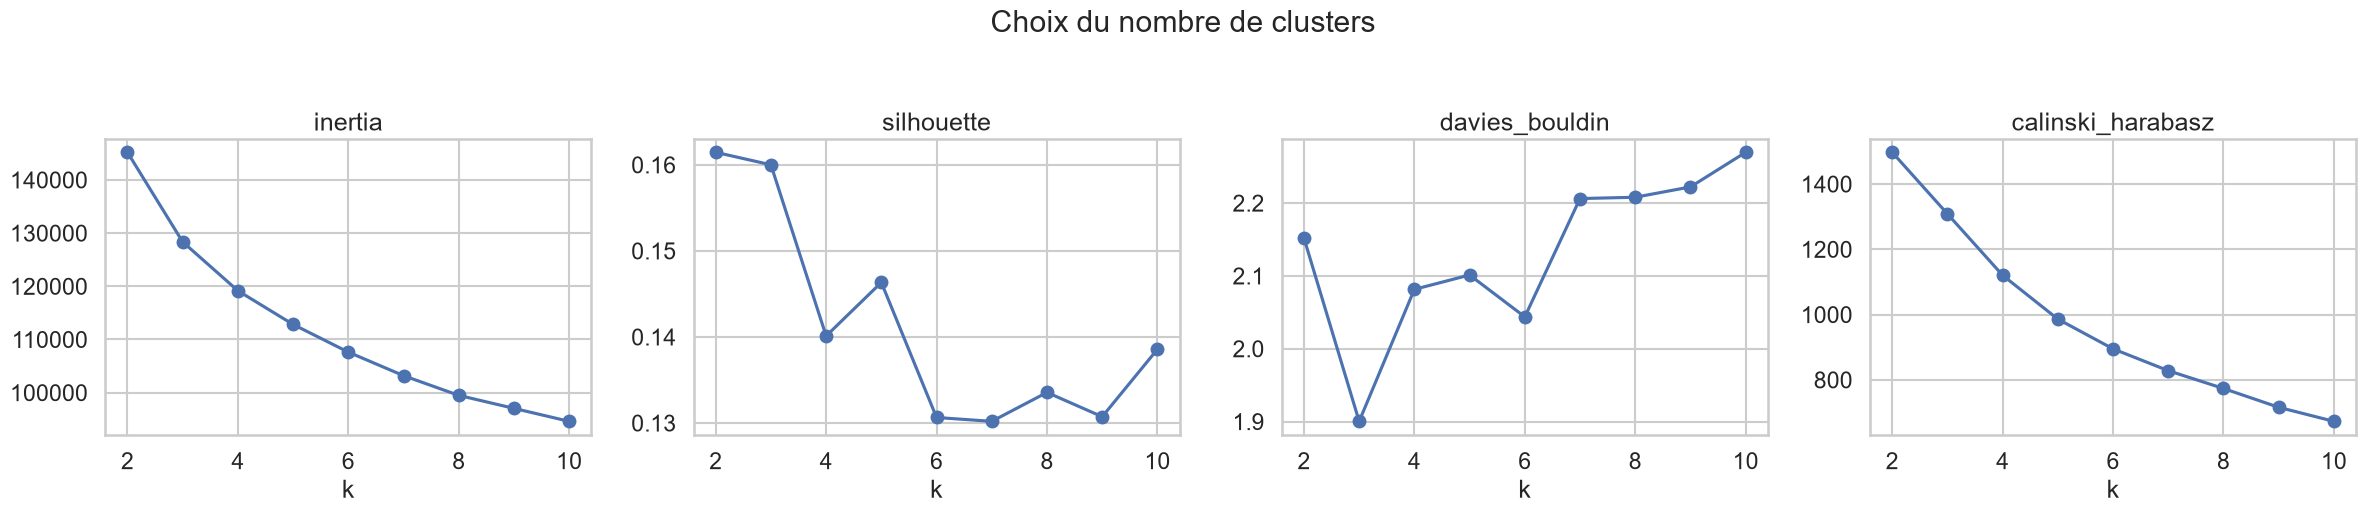

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, col in zip(axes, sweep.columns):
    ax.plot(sweep.index, sweep[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("k")
fig.suptitle("Choix du nombre de clusters", y=1.04)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/10_elbow_silhouette_kmeans.png", dpi=110, bbox_inches="tight")
plt.show()

In [5]:
print("meilleur k silhouette        :", sweep["silhouette"].idxmax())
print("meilleur k davies-bouldin    :", sweep["davies_bouldin"].idxmin())
print("meilleur k calinski-harabasz :", sweep["calinski_harabasz"].idxmax())

meilleur k silhouette        : 2
meilleur k davies-bouldin    : 3
meilleur k calinski-harabasz : 2


In [6]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED)
df["cluster"] = kmeans.fit_predict(X)
df["cluster"].value_counts().sort_index()

cluster
0    1718
1    2799
2    2526
Name: count, dtype: int64

## 3. Interprétation des profils

In [7]:
df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)
profile = df.groupby("cluster").agg(
    n=("ChurnNum", "size"),
    tenure=("tenure", "mean"),
    MonthlyCharges=("MonthlyCharges", "mean"),
    nb_services=("nb_services", "mean"),
    month_to_month=("is_month_to_month", "mean"),
    fiber=("is_fiber", "mean"),
    no_internet=("InternetService", lambda s: (s == "No").mean()),
    electronic_check=("is_electronic_check", "mean"),
    churn_rate=("ChurnNum", "mean"),
)
profile.round(2)

,n,tenure,MonthlyCharges,nb_services,month_to_month,fiber,no_internet,electronic_check,churn_rate
cluster,,,,,,,,,
0,1718,31.07,24.08,1.19,0.31,0.00,0.88,0.07,0.07
1,2799,14.05,68.54,2.26,0.97,0.58,0.00,0.55,0.49
2,2526,53.56,88.25,4.89,0.25,0.58,0.00,0.28,0.16


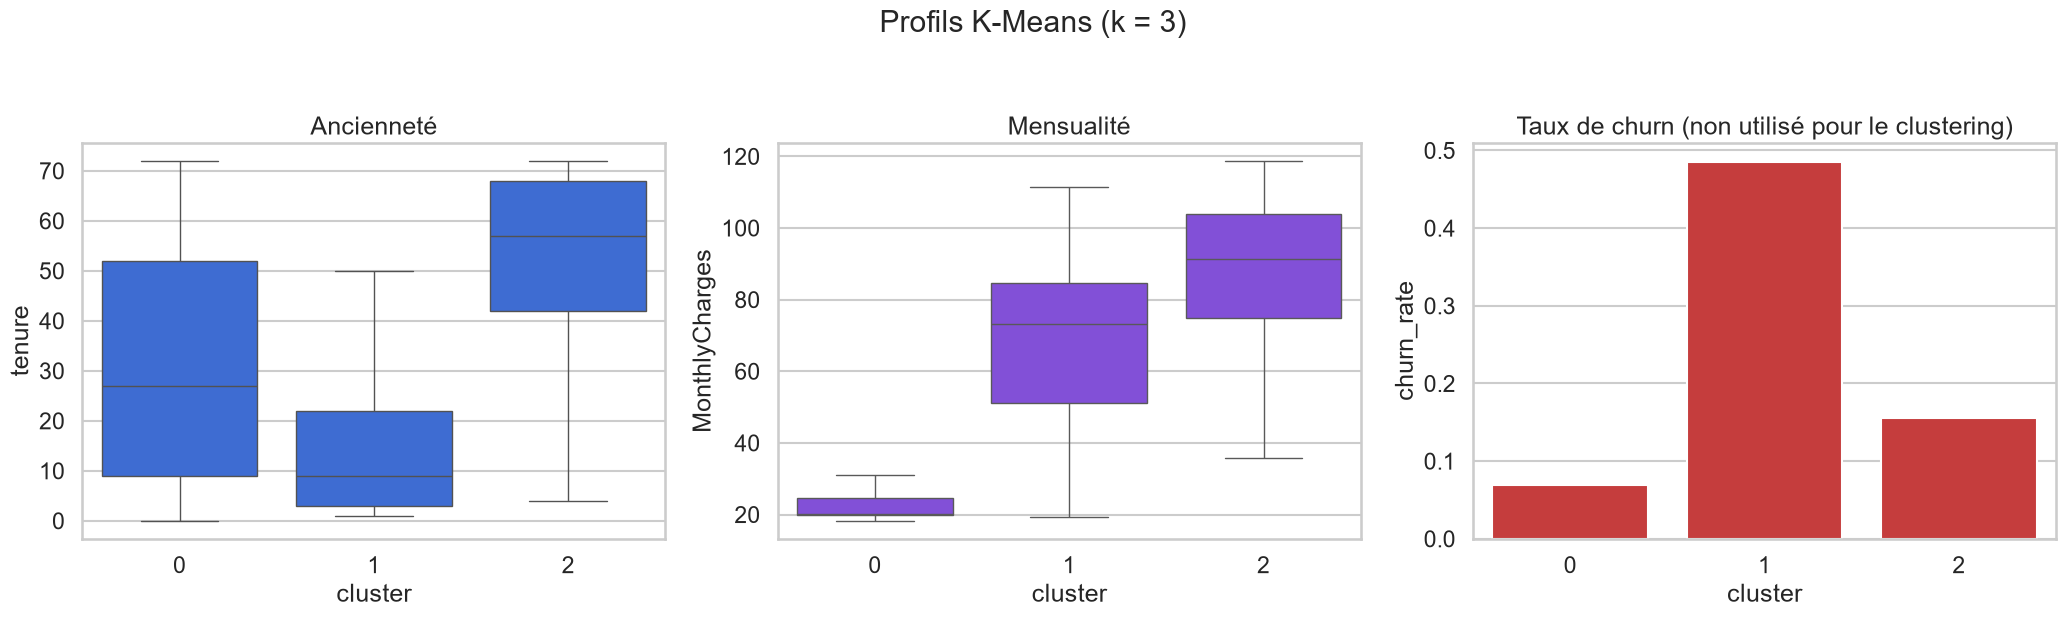

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
sns.boxplot(data=df, x="cluster", y="tenure", ax=axes[0], color="#2563eb", showfliers=False)
sns.boxplot(data=df, x="cluster", y="MonthlyCharges", ax=axes[1], color="#7c3aed", showfliers=False)
sns.barplot(x=profile.index, y=profile["churn_rate"], ax=axes[2], color="#dc2626")
axes[0].set_title("Ancienneté")
axes[1].set_title("Mensualité")
axes[2].set_title("Taux de churn (non utilisé pour le clustering)")
fig.suptitle(f"Profils K-Means (k = {K})", y=1.04)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/11_kmeans_profiles.png", dpi=110, bbox_inches="tight")
plt.show()